# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Fio Octriyanti
- **Email:** ds284b6x0623@student.devacademy.id
- **ID Dicoding:** DS284B6X0623


## Menentukan Pertanyaan Bisnis

Analisis ini menggunakan E-Commerce Public Dataset dari Olist. Fokus analisis adalah tren transaksi dan performa pengiriman untuk mendukung evaluasi operasional e-commerce.

**Pertanyaan 1 — Tren transaksi bulanan**

Bagaimana perubahan jumlah pesanan unik dan total nilai produk per bulan selama periode September 2016–Oktober 2018, serta pada bulan mana masing-masing metrik mencapai nilai tertinggi dan terendah?

**Pertanyaan 2 — Ketepatan pengiriman dan ulasan pelanggan**

Selama periode September 2016–Oktober 2018, bagaimana perbedaan rata-rata skor ulasan antara pesanan yang terlambat dan pesanan yang tiba tepat waktu atau lebih cepat, serta negara bagian mana yang memiliki tingkat keterlambatan tertinggi di antara wilayah dengan minimal 100 pesanan yang memiliki data pengiriman lengkap?

**Tujuan analisis**

1. Mengidentifikasi perubahan volume pesanan dan nilai produk untuk membantu perencanaan kapasitas operasional.
2. Membandingkan skor ulasan berdasarkan status pengiriman.
3. Mengidentifikasi wilayah yang perlu dievaluasi lebih lanjut berdasarkan tingkat keterlambatan dan jumlah observasi.

Pertanyaan tersebut dijawab menggunakan agregasi data, visualisasi, dan interpretasi hasil eksplorasi. Analisis bersifat deskriptif sehingga perbedaan skor ulasan tidak langsung dianggap sebagai bukti hubungan sebab-akibat.


**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Pertanyaan 1 — Tren transaksi bulanan**

Bagaimana perubahan jumlah pesanan unik dan total nilai produk per bulan selama periode September 2016–Oktober 2018, serta pada bulan mana masing-masing metrik mencapai nilai tertinggi dan terendah?

**Pertanyaan 2 — Ketepatan pengiriman dan ulasan pelanggan**

Selama periode September 2016–Oktober 2018, bagaimana perbedaan rata-rata skor ulasan antara pesanan yang terlambat dan pesanan yang tiba tepat waktu atau lebih cepat, serta negara bagian mana yang memiliki tingkat keterlambatan tertinggi di antara wilayah dengan minimal 100 pesanan yang memiliki data pengiriman lengkap?

## Import Semua Packages/Library yang Digunakan

In [3]:

%pip install pandas numpy matplotlib seaborn plotly scipy jupyter ipykernel


  Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (62 kB)
Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl (20.5 MB)
Note: you may need to restart the kernel to use updated packages.


In [4]:
# Data manipulation and numerical computation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Statistical analysis
from scipy import stats

# Date and time processing
from datetime import datetime, timedelta

# File and directory management
from pathlib import Path
import os

# Display settings for Jupyter Notebook
from IPython.display import display, Markdown

# Suppress unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

# Pandas display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# Matplotlib settings
plt.style.use("default")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

# Seaborn settings
sns.set_theme(style="whitegrid", palette="deep")

print("All libraries have been imported successfully!")
print(f"Pandas version : {pd.__version__}")
print(f"NumPy version  : {np.__version__}")


All libraries have been imported successfully!
Pandas version : 3.0.6
NumPy version  : 2.5.4


## Data Wrangling

### Gathering Data

#### Load dataset E-Commerce Public Dataset


In [5]:
from pathlib import Path
import pandas as pd
import numpy as np

# Menentukan lokasi folder data
DATA_DIR = Path("data")

# Memuat seluruh dataset yang akan digunakan
df1 = pd.read_csv(DATA_DIR / "data_1.csv")
df2 = pd.read_csv(DATA_DIR / "data_2.csv")

# Menampilkan konfirmasi proses loading
print("Dataset berhasil dimuat!")
print(f"Data 1: {df1.shape[0]:,} baris dan {df1.shape[1]} kolom")
print(f"Data 2: {df2.shape[0]:,} baris dan {df2.shape[1]} kolom")


Dataset berhasil dimuat!
Data 1: 25 baris dan 6 kolom
Data 2: 27 baris dan 6 kolom


In [6]:
print("DATASET 1")
display(df1.head())

print("\nDATASET 2")
display(df2.head())

DATASET 1


,purchase_month,orders,revenue,avg_review,avg_delivery_days,late_rate
0,2016-09,4,267.36,1.00,54.81,100.00
1,2016-10,324,"49,507.66",3.56,19.58,1.11
2,2016-12,1,10.90,5.00,4.69,0.00
3,2017-01,800,"120,312.87",4.06,12.65,3.07
4,2017-02,1780,"247,303.02",4.02,13.17,3.21



DATASET 2


,customer_state,orders,revenue,avg_review,avg_delivery_days,late_rate
0,SP,41746,"5,202,955.05",4.17,8.76,5.89
1,RJ,12852,"1,824,092.67",3.88,15.31,13.47
2,MG,11635,"1,585,308.03",4.14,12.01,5.62
3,RS,5466,"750,304.02",4.13,15.30,7.15
4,PR,5045,"683,083.76",4.18,11.99,5.00


In [7]:
print("INFORMASI DATASET 1")
df1.info()

print("\nINFORMASI DATASET 2")
df2.info()


INFORMASI DATASET 1
<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   purchase_month     25 non-null     str    
 1   orders             25 non-null     int64  
 2   revenue            25 non-null     float64
 3   avg_review         25 non-null     float64
 4   avg_delivery_days  23 non-null     float64
 5   late_rate          23 non-null     float64
dtypes: float64(4), int64(1), str(1)
memory usage: 1.5 KB

INFORMASI DATASET 2
<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_state     27 non-null     str    
 1   orders             27 non-null     int64  
 2   revenue            27 non-null     float64
 3   avg_review         27 non-null     float64
 4   avg_delivery_days  27 non-null     float64

**Insight:**
- Dataset Olist terdiri dari tabel pesanan, item pesanan, pembayaran, ulasan, dan pelanggan.
- Analisis menggunakan agregasi pada tingkat pesanan agar tabel item/pembayaran/ulasan tidak menggandakan hitungan pesanan.


### Assessing Data

#### Memeriksa kualitas data dan mengidentifikasi masalah


In [8]:

# Menghitung jumlah dan persentase missing value
def check_missing_values(df, dataset_name):
    missing_summary = pd.DataFrame({
        "Missing Count": df.isna().sum(),
        "Missing Percentage (%)": (df.isna().mean() * 100).round(2)
    })

    missing_summary = missing_summary[
        missing_summary["Missing Count"] > 0
    ].sort_values("Missing Count", ascending=False)

    print(f"Missing Value - {dataset_name}")

    if missing_summary.empty:
        print("Tidak ditemukan missing value.")
    else:
        display(missing_summary)

check_missing_values(df1, "Dataset 1")
check_missing_values(df2, "Dataset 2")


Missing Value - Dataset 1


,Missing Count,Missing Percentage (%)
avg_delivery_days,2,8.00
late_rate,2,8.00


Missing Value - Dataset 2
Tidak ditemukan missing value.


**Insight:** jika ada nilai kosong, perhatikan kolom tempat nilai tersebut muncul dan persentasenya. Nilai kosong pada kolom penting tidak selalu boleh langsung dihapus; bisa jadi nilai tersebut memang tidak tersedia atau tidak relevan untuk semua transaksi.

**Steps to Take:**
- Kolom tanggal pengiriman memiliki nilai kosong pada pesanan yang belum terkirim; nilai tersebut tidak diisi secara artifisial dan dikecualikan hanya dari analisis durasi pengiriman.
- Tabel item, pembayaran, dan ulasan dapat memiliki beberapa baris per `order_id`; karena itu data diagregasi per pesanan sebelum digabungkan.
- Baris duplikat dan pesanan tanpa timestamp pembelian dibersihkan pada tahap berikutnya.


In [9]:

def check_duplicates(df, dataset_name):
    duplicate_count = df.duplicated().sum()
    duplicate_percentage = (
        duplicate_count / len(df) * 100
        if len(df) > 0 else 0
    )

    print(f"Duplicate Data - {dataset_name}")
    print(f"Jumlah baris duplikat: {duplicate_count:,}")
    print(f"Persentase duplikat: {duplicate_percentage:.2f}%")

    if duplicate_count > 0:
        display(df[df.duplicated(keep=False)].head(10))

check_duplicates(df1, "Dataset 1")
check_duplicates(df2, "Dataset 2")


Duplicate Data - Dataset 1
Jumlah baris duplikat: 0
Persentase duplikat: 0.00%
Duplicate Data - Dataset 2
Jumlah baris duplikat: 0
Persentase duplikat: 0.00%


**Insight**: Perlu diingat, baris yang seluruh nilainya sama merupakan exact duplicate. Namun, jika terdapat beberapa baris dengan order_id sama, itu belum tentu duplikat karena satu pesanan dapat berisi beberapa item atau memiliki beberapa catatan terkait.

In [10]:

def inspect_columns(df, dataset_name):
    print(f"Pemeriksaan kolom - {dataset_name}")

    column_summary = pd.DataFrame({
        "Data Type": df.dtypes.astype(str),
        "Unique Values": df.nunique(dropna=True),
        "Missing Values": df.isna().sum()
    })

    display(column_summary)

    # Menampilkan contoh kategori pada kolom bertipe teks
    text_columns = df.select_dtypes(
        include=["object", "string", "category"]
    ).columns

    for column in text_columns:
        print(f"\nNilai unik pada kolom '{column}':")
        display(df[column].value_counts(dropna=False).head(10))

inspect_columns(df1, "Dataset 1")
inspect_columns(df2, "Dataset 2")


Pemeriksaan kolom - Dataset 1


,Data Type,Unique Values,Missing Values
purchase_month,str,25,0
orders,int64,24,0
revenue,float64,25,0
avg_review,float64,25,0
avg_delivery_days,float64,23,2
late_rate,float64,23,2



Nilai unik pada kolom 'purchase_month':


purchase_month
2016-09    1
2016-10    1
2016-12    1
2017-01    1
2017-02    1
2017-03    1
2017-04    1
2017-05    1
2017-06    1
2017-07    1
Name: count, dtype: int64

Pemeriksaan kolom - Dataset 2


,Data Type,Unique Values,Missing Values
customer_state,str,27,0
orders,int64,27,0
revenue,float64,27,0
avg_review,float64,27,0
avg_delivery_days,float64,27,0
late_rate,float64,27,0



Nilai unik pada kolom 'customer_state':


customer_state
SP    1
RJ    1
MG    1
RS    1
PR    1
SC    1
BA    1
DF    1
ES    1
GO    1
Name: count, dtype: int64

**Insight** : Cell ini dapat membantu menemukan kategori yang mungkin tidak konsisten, misalnya perbedaan huruf besar-kecil atau spasi tambahan. Periksa hasilnya dahulu sebelum menyamakan nilai karena tidak semua perbedaan penulisan berarti kesalahan.

In [11]:

def inspect_numeric_data(df, dataset_name):
    print(f"Statistik numerik - {dataset_name}")

    numeric_df = df.select_dtypes(include=np.number)

    if numeric_df.empty:
        print("Tidak ada kolom numerik untuk diperiksa.")
        return

    display(numeric_df.describe().T)

    # Pemeriksaan awal potensi outlier menggunakan metode IQR
    outlier_summary = []

    for column in numeric_df.columns:
        series = numeric_df[column].dropna()

        if series.empty:
            continue

        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outlier_count = (
            (series < lower_bound) | (series > upper_bound)
        ).sum()

        outlier_summary.append({
            "Column": column,
            "Lower Bound": lower_bound,
            "Upper Bound": upper_bound,
            "Potential Outliers": int(outlier_count)
        })

    display(pd.DataFrame(outlier_summary))

inspect_numeric_data(df1, "Dataset 1")
inspect_numeric_data(df2, "Dataset 2")


Statistik numerik - Dataset 1


,count,mean,std,min,25%,50%,75%,max
orders,25.00,"3,977.64","2,699.94",1.00,"1,780.00","4,285.00","6,512.00","7,544.00"
revenue,25.00,"543,665.75","367,072.10",0.00,"247,303.02","573,971.68","865,124.31","1,010,271.37"
avg_review,25.00,3.82,0.86,1.00,3.91,4.07,4.19,5.00
avg_delivery_days,23.00,14.32,9.38,4.69,11.37,12.01,15.04,54.81
late_rate,23.00,10.52,20.15,0.00,3.37,5.29,8.31,100.00


,Column,Lower Bound,Upper Bound,Potential Outliers
0,orders,"-5,318.00","13,610.00",0
1,revenue,"-679,428.92","1,791,856.25",0
2,avg_review,3.50,4.60,4
3,avg_delivery_days,5.87,20.54,2
4,late_rate,-4.03,15.71,3


Statistik numerik - Dataset 2


,count,mean,std,min,25%,50%,75%,max
orders,27.00,"3,683.00","8,270.44",46.00,381.50,907.00,"2,760.00","41,746.00"
revenue,27.00,"503,394.21","1,040,224.19","7,829.43","69,617.83","156,453.53","406,976.96","5,202,955.05"
avg_review,27.00,4.00,0.16,3.61,3.87,4.05,4.11,4.21
avg_delivery_days,27.00,18.78,4.91,8.76,15.46,19.28,21.39,29.39
late_rate,27.00,10.44,5.10,2.88,6.33,10.80,13.12,23.93


,Column,Lower Bound,Upper Bound,Potential Outliers
0,orders,"-3,186.25","6,327.75",3
1,revenue,"-436,420.87","913,015.67",3
2,avg_review,3.51,4.46,0
3,avg_delivery_days,6.56,30.30,0
4,late_rate,-3.85,23.31,1


**Insight**: metode IQR hanya menandai potential outlier, bukan otomatis menyatakan bahwa nilai tersebut salah. Pada data e-commerce, transaksi bernilai besar atau durasi pengiriman panjang bisa saja benar-benar terjadi.

### Cleaning Data

#### Membersihkan dan menggabungkan data


In [12]:

# ============================================================
# 2.3 CLEANING DATA
# ============================================================

# Membuat salinan agar data hasil gathering tetap tersedia
df1_clean = df1.copy()
df2_clean = df2.copy()


def clean_basic_data(df, dataset_name):
    print(f"Cleaning {dataset_name}")
    initial_rows = len(df)

    # 1. Mengubah string kosong atau hanya berisi spasi menjadi NaN
    text_columns = df.select_dtypes(
        include=["object", "string"]
    ).columns

    for column in text_columns:
        df[column] = df[column].replace(
            r"^\s*$", np.nan, regex=True
        )

        # 2. Menghapus spasi di awal dan akhir teks
        df[column] = df[column].map(
            lambda value: value.strip()
            if isinstance(value, str) else value
        )

    # 3. Menghapus baris yang identik sepenuhnya
    duplicate_count = df.duplicated().sum()
    df.drop_duplicates(inplace=True)

    removed_rows = initial_rows - len(df)

    print(f"Jumlah baris awal: {initial_rows:,}")
    print(f"Baris duplikat dihapus: {duplicate_count:,}")
    print(f"Total baris yang dihapus: {removed_rows:,}")
    print(f"Jumlah baris setelah cleaning: {len(df):,}")

    return df


df1_clean = clean_basic_data(df1_clean, "Dataset 1")
print()
df2_clean = clean_basic_data(df2_clean, "Dataset 2")


Cleaning Dataset 1
Jumlah baris awal: 25
Baris duplikat dihapus: 0
Total baris yang dihapus: 0
Jumlah baris setelah cleaning: 25

Cleaning Dataset 2
Jumlah baris awal: 27
Baris duplikat dihapus: 0
Total baris yang dihapus: 0
Jumlah baris setelah cleaning: 27


**Insight:**
- Data dibentuk menjadi satu baris per pesanan; item, pembayaran, dan ulasan diagregasi terlebih dahulu.
- Durasi pengiriman hanya tersedia pada pesanan yang memiliki tanggal pembelian dan tanggal diterima.


In [13]:

# Membandingkan kondisi missing value sebelum dan sesudah cleaning
def compare_missing_values(df_before, df_after, dataset_name):
    comparison = pd.DataFrame({
        "Missing Before": df_before.isna().sum(),
        "Missing After": df_after.isna().sum()
    })

    comparison = comparison[
        (comparison["Missing Before"] > 0) |
        (comparison["Missing After"] > 0)
    ]

    print(f"Perbandingan missing value - {dataset_name}")

    if comparison.empty:
        print("Tidak ditemukan missing value.")
    else:
        display(comparison)

compare_missing_values(df1, df1_clean, "Dataset 1")
compare_missing_values(df2, df2_clean, "Dataset 2")


Perbandingan missing value - Dataset 1


,Missing Before,Missing After
avg_delivery_days,2,2
late_rate,2,2


Perbandingan missing value - Dataset 2
Tidak ditemukan missing value.


In [14]:

# Memastikan hasil cleaning sudah diperiksa kembali
for dataset_name, df in [
    ("Dataset 1", df1_clean),
    ("Dataset 2", df2_clean)
]:
    print(f"\n{'=' * 50}")
    print(dataset_name)
    print(f"{'=' * 50}")

    print(f"Ukuran data: {df.shape}")
    print(f"Jumlah exact duplicate: {df.duplicated().sum()}")
    print(f"Total missing value: {df.isna().sum().sum()}")

    print("\nMissing value per kolom:")
    display(
        df.isna().sum()
        .loc[lambda x: x > 0]
        .to_frame("Missing Count")
    )

    print("\nContoh data setelah cleaning:")
    display(df.head())



Dataset 1
Ukuran data: (25, 6)
Jumlah exact duplicate: 0
Total missing value: 4

Missing value per kolom:


,Missing Count
avg_delivery_days,2
late_rate,2



Contoh data setelah cleaning:


,purchase_month,orders,revenue,avg_review,avg_delivery_days,late_rate
0,2016-09,4,267.36,1.00,54.81,100.00
1,2016-10,324,"49,507.66",3.56,19.58,1.11
2,2016-12,1,10.90,5.00,4.69,0.00
3,2017-01,800,"120,312.87",4.06,12.65,3.07
4,2017-02,1780,"247,303.02",4.02,13.17,3.21



Dataset 2
Ukuran data: (27, 6)
Jumlah exact duplicate: 0
Total missing value: 0

Missing value per kolom:


,Missing Count



Contoh data setelah cleaning:


,customer_state,orders,revenue,avg_review,avg_delivery_days,late_rate
0,SP,41746,"5,202,955.05",4.17,8.76,5.89
1,RJ,12852,"1,824,092.67",3.88,15.31,13.47
2,MG,11635,"1,585,308.03",4.14,12.01,5.62
3,RS,5466,"750,304.02",4.13,15.30,7.15
4,PR,5045,"683,083.76",4.18,11.99,5.00


In [15]:

# Menyimpan data hasil cleaning
OUTPUT_DIR = Path("data/cleaned")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df1_clean.to_csv(
    OUTPUT_DIR / "data_1_clean.csv",
    index=False
)

df2_clean.to_csv(
    OUTPUT_DIR / "data_2_clean.csv",
    index=False
)

print("Dataset hasil cleaning berhasil disimpan.")
print(f"Lokasi penyimpanan: {OUTPUT_DIR.resolve()}")


Dataset hasil cleaning berhasil disimpan.
Lokasi penyimpanan: /Users/ofinovyanti/Fio's Documents/Semester 5/Activity/Asah/Task/Proyek Analisis Data_DS284B6X0623/data/cleaned


## Exploratory Data Analysis (EDA)

### Eksplorasi tren pesanan dan performa pengiriman


In [16]:

# Melihat kolom yang tersedia pada dataset hasil cleaning

print("Kolom Dataset 1:")
print(df1_clean.columns.tolist())

print("\nKolom Dataset 2:")
print(df2_clean.columns.tolist())

print("\nUkuran dataset:")
print("Dataset 1:", df1_clean.shape)
print("Dataset 2:", df2_clean.shape)


Kolom Dataset 1:
['purchase_month', 'orders', 'revenue', 'avg_review', 'avg_delivery_days', 'late_rate']

Kolom Dataset 2:
['customer_state', 'orders', 'revenue', 'avg_review', 'avg_delivery_days', 'late_rate']

Ukuran dataset:
Dataset 1: (25, 6)
Dataset 2: (27, 6)


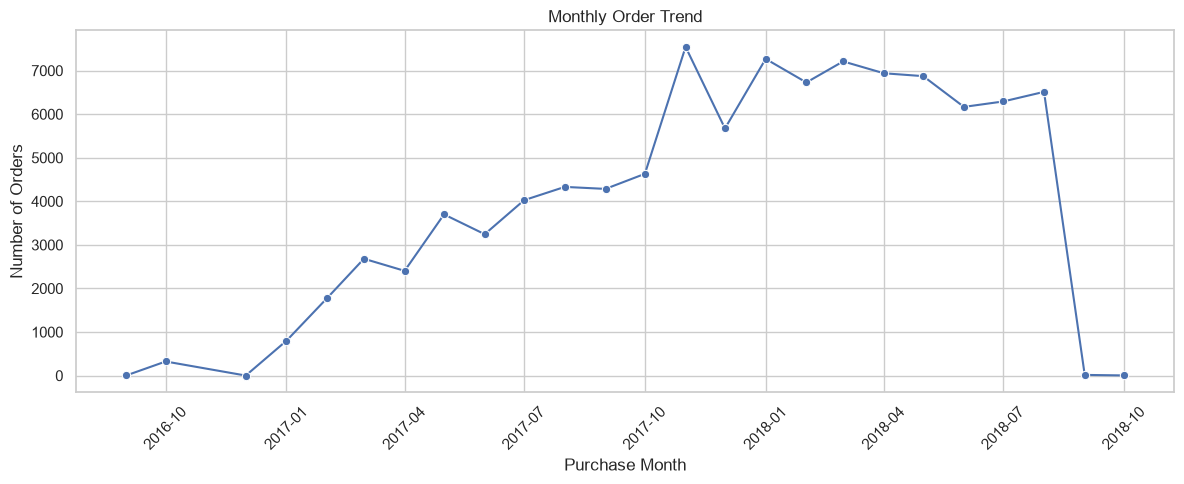

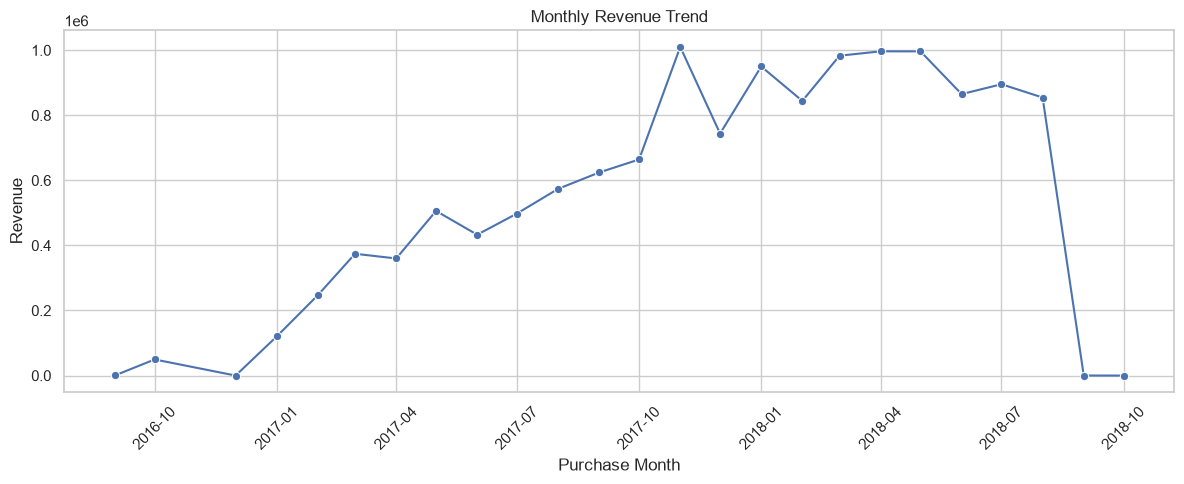

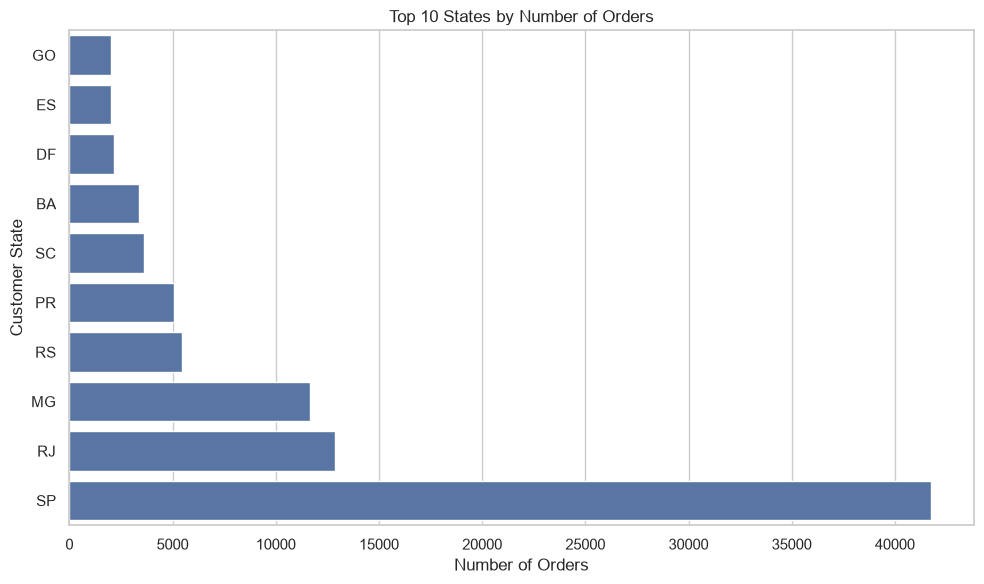

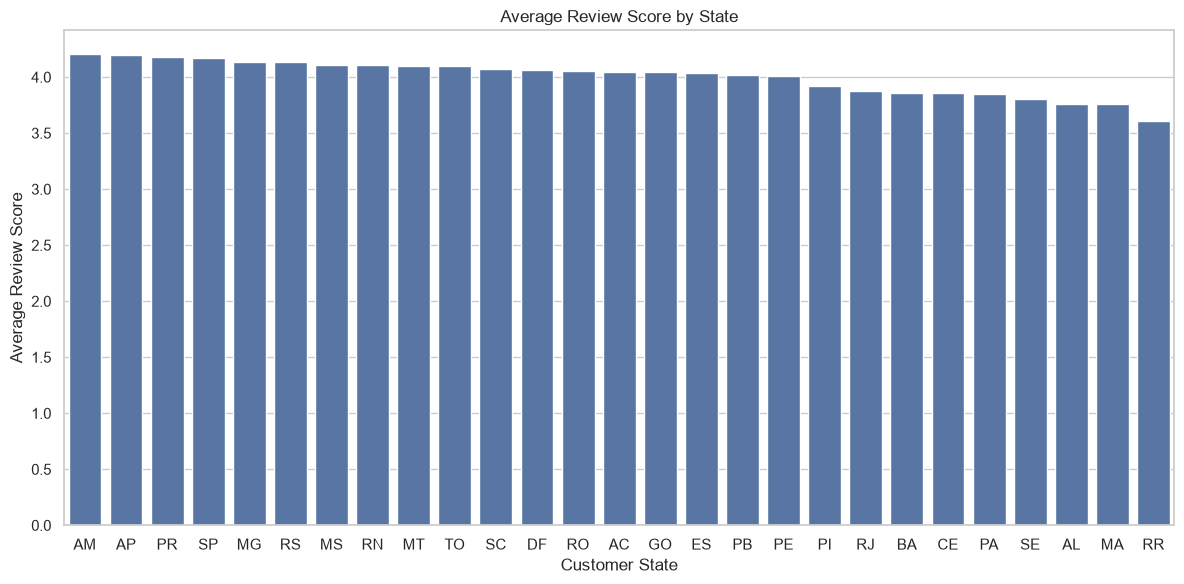

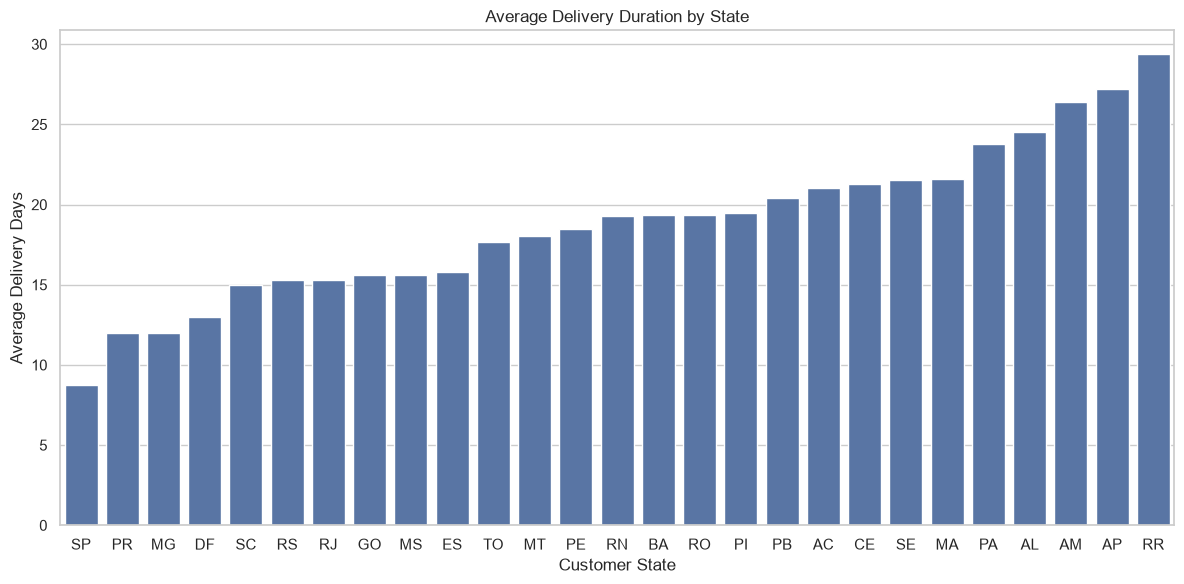

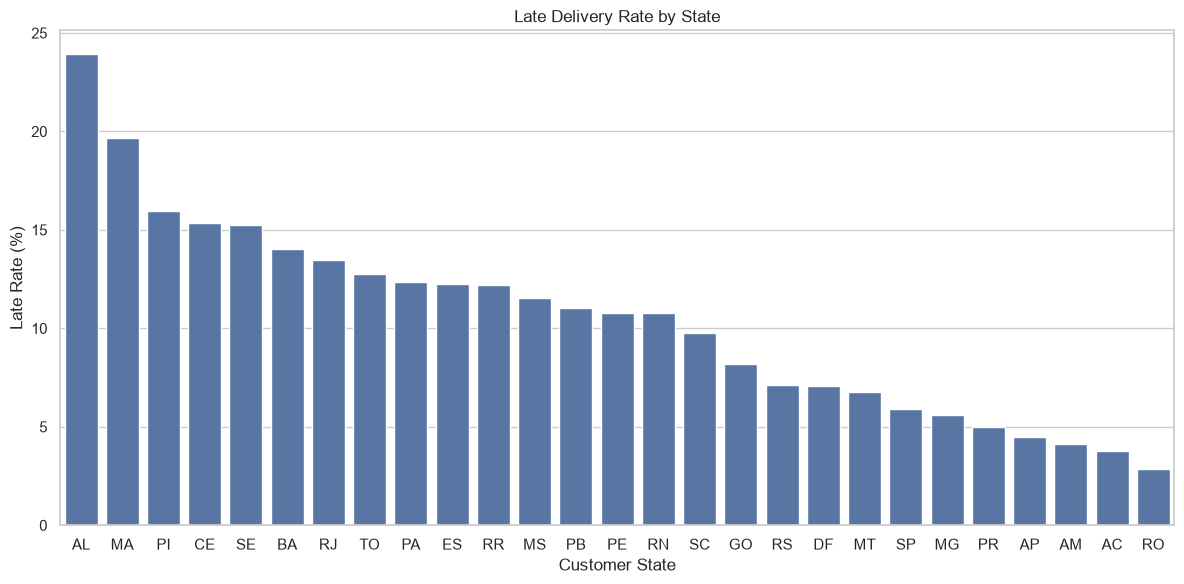

In [22]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Gunakan dataset hasil cleaning
df_monthly = df1_clean.copy()
df_state = df2_clean.copy()

# Pastikan format kolom bulan dan urutan waktu benar
df_monthly["purchase_month"] = pd.to_datetime(
    df_monthly["purchase_month"], format="%Y-%m", errors="coerce"
)
df_monthly = df_monthly.sort_values("purchase_month")

# Pastikan metrik numerik
metrics = [
    "orders", "revenue", "avg_review",
    "avg_delivery_days", "late_rate"
]

for col in metrics:
    df_monthly[col] = pd.to_numeric(df_monthly[col], errors="coerce")
    df_state[col] = pd.to_numeric(df_state[col], errors="coerce")

sns.set_theme(style="whitegrid")

# 1. Tren jumlah pesanan bulanan
plt.figure(figsize=(12, 5))
sns.lineplot(data=df_monthly, x="purchase_month", y="orders", marker="o")
plt.title("Monthly Order Trend")
plt.xlabel("Purchase Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Tren pendapatan bulanan
plt.figure(figsize=(12, 5))
sns.lineplot(data=df_monthly, x="purchase_month", y="revenue", marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Purchase Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Sepuluh negara bagian dengan jumlah pesanan tertinggi
top_states = df_state.nlargest(10, "orders").sort_values("orders")

plt.figure(figsize=(10, 6))
sns.barplot(data=top_states, x="orders", y="customer_state")
plt.title("Top 10 States by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Customer State")
plt.tight_layout()
plt.show()

# 4. Rata-rata rating per negara bagian
rating_states = df_state.sort_values("avg_review", ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(data=rating_states, x="customer_state", y="avg_review")
plt.title("Average Review Score by State")
plt.xlabel("Customer State")
plt.ylabel("Average Review Score")
plt.tight_layout()
plt.show()

# 5. Durasi pengiriman rata-rata per negara bagian
delivery_states = df_state.sort_values("avg_delivery_days")

plt.figure(figsize=(12, 6))
sns.barplot(data=delivery_states, x="customer_state", y="avg_delivery_days")
plt.title("Average Delivery Duration by State")
plt.xlabel("Customer State")
plt.ylabel("Average Delivery Days")
plt.tight_layout()
plt.show()

# 6. Tingkat keterlambatan per negara bagian
late_states = df_state.sort_values("late_rate", ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(data=late_states, x="customer_state", y="late_rate")
plt.title("Late Delivery Rate by State")
plt.xlabel("Customer State")
plt.ylabel("Late Rate (%)")
plt.tight_layout()
plt.show()


### 1. Monthly Order and Revenue Trends
- Ringkasan bulanan menunjukkan perubahan jumlah pesanan dan pendapatan dari waktu ke waktu. Informasi ini dapat digunakan untuk mengidentifikasi periode dengan aktivitas transaksi tinggi maupun rendah.
- Tren tersebut dapat menjadi dasar perencanaan kapasitas operasional, pengelolaan sumber daya, dan penentuan waktu promosi yang lebih tepat.
- Perubahan rata-rata rating, durasi pengiriman, dan tingkat keterlambatan juga perlu diperhatikan untuk mengevaluasi apakah kualitas layanan tetap terjaga ketika jumlah pesanan meningkat.

### 2. Customer State Performance
- Ringkasan per negara bagian memungkinkan perbandingan jumlah pesanan dan pendapatan untuk mengetahui wilayah yang memberikan kontribusi terbesar terhadap aktivitas bisnis.
- Perbedaan rata-rata rating pelanggan dapat digunakan untuk mengidentifikasi wilayah yang memiliki pengalaman pelanggan relatif lebih baik atau memerlukan evaluasi layanan lebih lanjut.
- Perbandingan rata-rata durasi pengiriman dan tingkat keterlambatan dapat membantu mengidentifikasi wilayah yang menghadapi tantangan dalam proses logistik.
- Hasil analisis dapat menjadi pertimbangan dalam menentukan prioritas evaluasi pengiriman dan peningkatan kualitas layanan di setiap wilayah.

### 3. Business Recommendations
- Gunakan tren bulanan sebagai salah satu dasar perencanaan operasional dan promosi, dengan tetap mempertimbangkan pola permintaan yang teramati.
- Prioritaskan evaluasi logistik pada negara bagian dengan durasi pengiriman atau tingkat keterlambatan yang relatif tinggi.
- Evaluasi rating pelanggan bersama metrik pengiriman untuk melihat apakah wilayah dengan masalah logistik juga menunjukkan kepuasan pelanggan yang lebih rendah.


## Visualization & Explanatory Analysis

## Pertanyaan 1 — Tren Transaksi Bulanan

**Bagaimana perubahan jumlah pesanan unik dan total nilai produk per bulan selama periode September 2016–Oktober 2018, serta pada bulan mana masing-masing metrik mencapai nilai tertinggi dan terendah?**

### Tujuan Analisis

1. Mengidentifikasi tren jumlah pesanan unik setiap bulan.
2. Mengamati perubahan total nilai produk setiap bulan.
3. Menentukan bulan dengan jumlah pesanan unik dan total nilai produk tertinggi serta terendah.

### Metrik Analisis

- **Jumlah pesanan unik:** total pesanan berbeda (`orders`) setiap bulan.
- **Total nilai produk:** total nilai transaksi produk (`revenue`) setiap bulan.
- **Periode analisis:** September 2016–Oktober 2018.


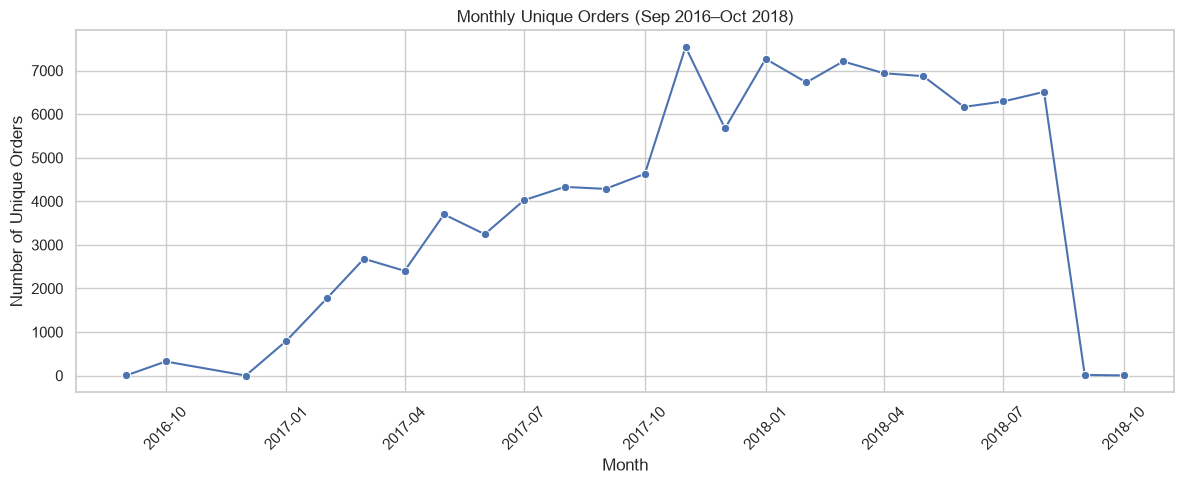

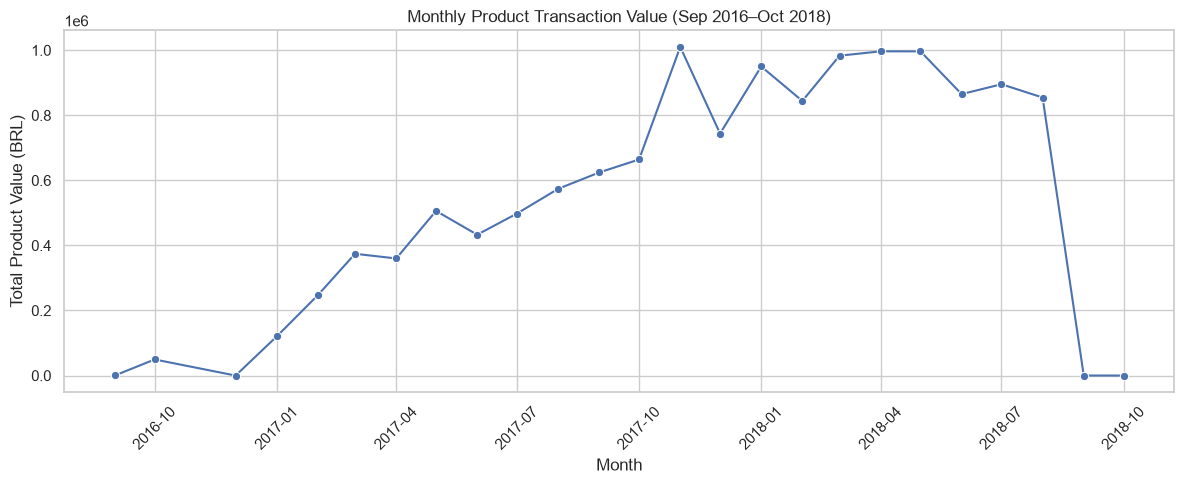

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Gunakan dataframe bulanan yang sudah tersedia
df_trend = df1_clean.copy()

# Pastikan format tanggal dan nilai numerik benar
df_trend["purchase_month"] = pd.to_datetime(
    df_trend["purchase_month"], errors="coerce"
)
df_trend["orders"] = pd.to_numeric(
    df_trend["orders"], errors="coerce"
)
df_trend["revenue"] = pd.to_numeric(
    df_trend["revenue"], errors="coerce"
)

# Filter periode September 2016–Oktober 2018
df_trend = df_trend[
    df_trend["purchase_month"].between(
        "2016-09-01", "2018-10-31"
    )
].dropna(
    subset=["purchase_month", "orders", "revenue"]
).sort_values("purchase_month")

sns.set_theme(style="whitegrid")

# Visualisasi jumlah pesanan unik
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=df_trend,
    x="purchase_month",
    y="orders",
    marker="o"
)
plt.title("Monthly Unique Orders (Sep 2016–Oct 2018)")
plt.xlabel("Month")
plt.ylabel("Number of Unique Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Visualisasi total nilai produk
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=df_trend,
    x="purchase_month",
    y="revenue",
    marker="o"
)
plt.title("Monthly Product Transaction Value (Sep 2016–Oct 2018)")
plt.xlabel("Month")
plt.ylabel("Total Product Value (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
# Bulan dengan jumlah pesanan tertinggi dan terendah
max_orders = df_trend.loc[df_trend["orders"].idxmax()]
min_orders = df_trend.loc[df_trend["orders"].idxmin()]

# Bulan dengan nilai produk tertinggi dan terendah
max_revenue = df_trend.loc[df_trend["revenue"].idxmax()]
min_revenue = df_trend.loc[df_trend["revenue"].idxmin()]

print("JUMLAH PESANAN UNIK")
print(
    f"Tertinggi : {max_orders['purchase_month']:%B %Y} "
    f"({max_orders['orders']:,.0f} pesanan)"
)
print(
    f"Terendah  : {min_orders['purchase_month']:%B %Y} "
    f"({min_orders['orders']:,.0f} pesanan)"
)

print("\nTOTAL NILAI PRODUK")
print(
    f"Tertinggi : {max_revenue['purchase_month']:%B %Y} "
    f"(BRL {max_revenue['revenue']:,.2f})"
)
print(
    f"Terendah  : {min_revenue['purchase_month']:%B %Y} "
    f"(BRL {min_revenue['revenue']:,.2f})"
)

JUMLAH PESANAN UNIK
Tertinggi : November 2017 (7,544 pesanan)
Terendah  : December 2016 (1 pesanan)

TOTAL NILAI PRODUK
Tertinggi : November 2017 (BRL 1,010,271.37)
Terendah  : October 2018 (BRL 0.00)


### Insight Pertanyaan Bisnis 1

Berdasarkan hasil analisis, jumlah pesanan unik dan total nilai produk mencapai nilai tertinggi pada **November 2017**, dengan **7.544 pesanan** dan total nilai produk sebesar **BRL 1.010.271,37**. Hal ini menunjukkan bahwa November 2017 merupakan periode dengan aktivitas transaksi dan nilai produk tertinggi selama periode pengamatan.

Sebaliknya, jumlah pesanan unik terendah terjadi pada **Desember 2016**, yaitu hanya **1 pesanan**, sedangkan total nilai produk terendah terjadi pada **Oktober 2018**, yaitu **BRL 0,00**. Nilai tersebut perlu ditafsirkan dengan mempertimbangkan cakupan data pada awal dan akhir periode pengamatan.

**Kesimpulan:** November 2017 menjadi periode puncak berdasarkan kedua metrik transaksi. Sementara itu, nilai terendah pada Desember 2016 dan Oktober 2018 perlu diperiksa lebih lanjut untuk memastikan apakah mencerminkan aktivitas transaksi yang rendah atau data yang belum mencakup satu bulan penuh.

### Pertanyaan Bisnis 2

**Berapa perbedaan rata-rata skor ulasan pelanggan antara pesanan yang terlambat dan tepat waktu untuk pesanan yang diterima pada Januari–Agustus 2018, dan bagaimana perbedaan tersebut dapat digunakan untuk menentukan prioritas evaluasi proses pengiriman?**

**Tujuan Analisis**

1. Membandingkan rata-rata skor ulasan pelanggan antara pesanan yang terlambat dan tepat waktu.
2. Menghitung selisih rata-rata skor ulasan kedua kelompok.
3. Menggunakan hasil perbandingan sebagai dasar untuk menentukan prioritas evaluasi proses pengiriman.

**Metrik Analisis**

- **Rata-rata skor ulasan:** rata-rata `review_score` untuk setiap kelompok pengiriman.
- **Status pengiriman:** terlambat jika tanggal diterima pelanggan melewati tanggal estimasi; tepat waktu jika diterima pada atau sebelum tanggal estimasi.
- **Periode analisis:** Januari–Agustus 2018, berdasarkan tanggal pesanan diterima pelanggan.


,avg_review,total_reviews
delivery_status,,
Tepat Waktu,4.30,49544
Terlambat,2.51,5539


Selisih rata-rata skor: 1.79 poin


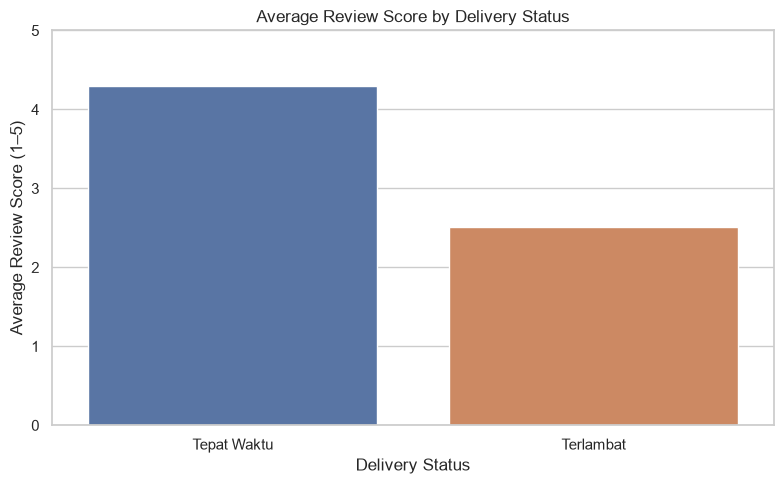

In [35]:
# Ringkasan rata-rata skor ulasan per status pengiriman
summary = (
    df_review.groupby("delivery_status")
    .agg(
        avg_review=("review_score", "mean"),
        total_reviews=("review_score", "count")
    )
    .reindex(["Tepat Waktu", "Terlambat"])
)

display(summary.round(2))

# Selisih rata-rata skor ulasan
difference = (
    summary.loc["Tepat Waktu", "avg_review"]
    - summary.loc["Terlambat", "avg_review"]
)

print(f"Selisih rata-rata skor: {difference:.2f} poin")

# Visualisasi
plt.figure(figsize=(8, 5))

sns.barplot(
    data=summary.reset_index(),
    x="delivery_status",
    y="avg_review",
    hue="delivery_status",
    order=["Tepat Waktu", "Terlambat"],
    hue_order=["Tepat Waktu", "Terlambat"],
    legend=False
)

plt.title("Average Review Score by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score (1–5)")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

### Insight Pertanyaan Bisnis 2

Hasil analisis menunjukkan bahwa pesanan yang dikirim tepat waktu memperoleh rata-rata skor ulasan sebesar **4,30**, sedangkan pesanan yang terlambat memperoleh rata-rata skor sebesar **2,51**.

Selisih rata-rata skor ulasan antara kedua kelompok adalah **1,79 poin**. Hasil ini menunjukkan bahwa pesanan yang dikirim tepat waktu memiliki rata-rata skor ulasan lebih tinggi dibandingkan pesanan yang terlambat. Analisis mencakup 49.544 ulasan pada kelompok tepat waktu dan 5.539 ulasan pada kelompok terlambat.

Perbedaan tersebut dapat menjadi dasar untuk menentukan prioritas evaluasi proses pengiriman. Karena pesanan terlambat memiliki rata-rata skor ulasan yang lebih rendah, evaluasi dapat diprioritaskan pada ketepatan waktu pengiriman dan proses distribusi. Namun, perbedaan skor ini belum membuktikan bahwa keterlambatan merupakan satu-satunya penyebab rendahnya kepuasan pelanggan.

**Kesimpulan:** Perbandingan rata-rata skor ulasan menunjukkan adanya hubungan antara ketepatan waktu pengiriman dan pengalaman pelanggan selama Januari–Agustus 2018. Pesanan yang dikirim tepat waktu memperoleh rata-rata skor lebih tinggi, sehingga proses pengiriman yang terlambat perlu menjadi salah satu prioritas evaluasi.

## 5. Conclusion & Recommendation

### 5.1 Conclusion

Berdasarkan hasil analisis dan visualisasi data, diperoleh kesimpulan sebagai berikut.

1. **Tren transaksi bulanan:** Jumlah pesanan unik dan total nilai produk mencapai nilai tertinggi pada November 2017, masing-masing sebesar **7.544 pesanan** dan **BRL 1.010.271,37**. Sebaliknya, jumlah pesanan terendah tercatat pada Desember 2016 sebanyak **1 pesanan**, sedangkan total nilai produk terendah terjadi pada Oktober 2018 sebesar **BRL 0,00**. Hasil ini menunjukkan bahwa November 2017 merupakan periode dengan aktivitas transaksi dan nilai produk tertinggi. Nilai ekstrem pada Desember 2016 dan Oktober 2018 perlu ditinjau dengan mempertimbangkan kelengkapan data pada awal dan akhir periode pengamatan.

2. **Hubungan ketepatan waktu pengiriman dengan ulasan pelanggan:** Pesanan yang dikirim tepat waktu memperoleh rata-rata skor ulasan sebesar **4,30**, sedangkan pesanan yang terlambat memperoleh rata-rata **2,51**. Terdapat selisih sebesar **1,79 poin**, dengan kelompok pesanan tepat waktu memiliki skor ulasan yang lebih tinggi. Temuan ini menunjukkan adanya hubungan antara ketepatan waktu pengiriman dan pengalaman pelanggan. Namun, hasil perbandingan ini belum membuktikan bahwa keterlambatan pengiriman merupakan satu-satunya faktor yang memengaruhi skor ulasan.

### 5.2 Recommendation

Berdasarkan kesimpulan tersebut, rekomendasi tindakan yang dapat dilakukan adalah:

1. **Mengevaluasi proses pengiriman yang terlambat.** Perusahaan perlu meninjau penyebab keterlambatan berdasarkan estimasi dan tanggal aktual pengiriman, kemudian mengidentifikasi tahapan distribusi atau wilayah yang memerlukan perbaikan. Evaluasi ini dapat membantu menentukan prioritas perbaikan layanan pengiriman.

2. **Memvalidasi data pada periode dengan nilai ekstrem.** Periksa kembali data Desember 2016 dan Oktober 2018 untuk memastikan bahwa jumlah pesanan dan nilai produk mencerminkan kondisi transaksi sebenarnya, bukan akibat periode pengamatan yang belum lengkap atau masalah pencatatan data.

3. **Memantau ketepatan waktu pengiriman dan skor ulasan secara berkala.** Perusahaan dapat menggunakan rata-rata skor ulasan dan tingkat keterlambatan sebagai indikator evaluasi layanan. Pemantauan berkala dapat membantu menilai apakah perbaikan proses pengiriman diikuti oleh peningkatan pengalaman pelanggan.